In [47]:
from datetime import datetime
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [6]:
start_date = datetime(2024,9,30)
end_date = datetime(2027,3,30)

In [13]:
coupon_rate = 0.01 / 100 # выплачивается в конце

H = 1000 # номинальная стоимость СО
extra_dates = [
    datetime(2025,1,15), datetime(2025,4,4), datetime(2025,7,4),datetime(2025,10,6),
    datetime(2026,1,14), datetime(2026,4,3), datetime(2026,7,6),datetime(2026,10,6),
    datetime(2027,1,13), datetime(2027,4,6)
]
extra_rate = 0.05

P = 0.0001
Q = 2.93987 # коэф кол-ва акций
T = 0.13
extra_income = H * extra_rate * len(extra_dates) * (1 - T)



def final_value_BA(fin_price_BA, Q, P, divs_fact, T):
    return fin_price_BA + (Q / P) * ((1 - T) * divs_fact)

def payout(H, P, S, Q, divs_plan, T):
    return H + P * S - Q * (divs_plan * (1 - T))

divs_plan = 190.60

In [28]:
scenarios_price = []
initial_price = 641
price_scenarios_pct = [0, 25, 50, 75, 90, 100, 110, 125, 150, 200]

for price_pct in price_scenarios_pct:
    final_price = initial_price * (price_pct / 100.0)
    
    S = final_value_BA(final_price, Q, P, divs_plan, T)
    final_payout = payout(H, P, S, Q, divs_plan, T)
    total_payout = final_payout + extra_income
    
    scenarios_price.append({
        "Цена акции (% от нач.)": f"{price_pct}%",
        "Фин. цена (руб)": round(final_price, 2),
        "Выплата при погашении": round(total_payout, 2),
        "% от номинала": round(final_payout / H, 4) * 100,
    })

df_price = pd.DataFrame(scenarios_price)
print(df_price.to_string(index=False))

Цена акции (% от нач.)  Фин. цена (руб)  Выплата при погашении  % от номинала
                    0%             0.00                1435.00         100.00
                   25%           160.25                1435.02         100.00
                   50%           320.50                1435.03         100.00
                   75%           480.75                1435.05         100.00
                   90%           576.90                1435.06         100.01
                  100%           641.00                1435.06         100.01
                  110%           705.10                1435.07         100.01
                  125%           801.25                1435.08         100.01
                  150%           961.50                1435.10         100.01
                  200%          1282.00                1435.13         100.01


In [29]:
scenarios_div = []
div_scenarios_pct = [0, 25, 50, 75, 100, 125] 
fixed_final_price = 641
for div_pct in div_scenarios_pct:
    sum_div_fact = divs_plan * (div_pct / 100.0)
    
    S = final_value_BA(fixed_final_price, Q, P, sum_div_fact, T)
    final_payout = payout(H, P, S, Q, divs_plan, T)
    total_payout = final_payout + extra_income
    
    scenarios_div.append({
        "Факт. див. в % от плана": f"{div_pct}%",
        "Факт див": round(sum_div_fact, 2),
        "Выплата при погашении": round(total_payout, 2),
        "% от номинала": round(final_payout / H, 4) * 100,
    })

df_div = pd.DataFrame(scenarios_div)
print(df_div.to_string(index=False))

Факт. див. в % от плана  Факт див  Выплата при погашении  % от номинала
                     0%      0.00                 947.57          51.26
                    25%     47.65                1069.44          63.44
                    50%     95.30                1191.32          75.63
                    75%    142.95                1313.19          87.82
                   100%    190.60                1435.06         100.01
                   125%    238.25                1556.94         112.19


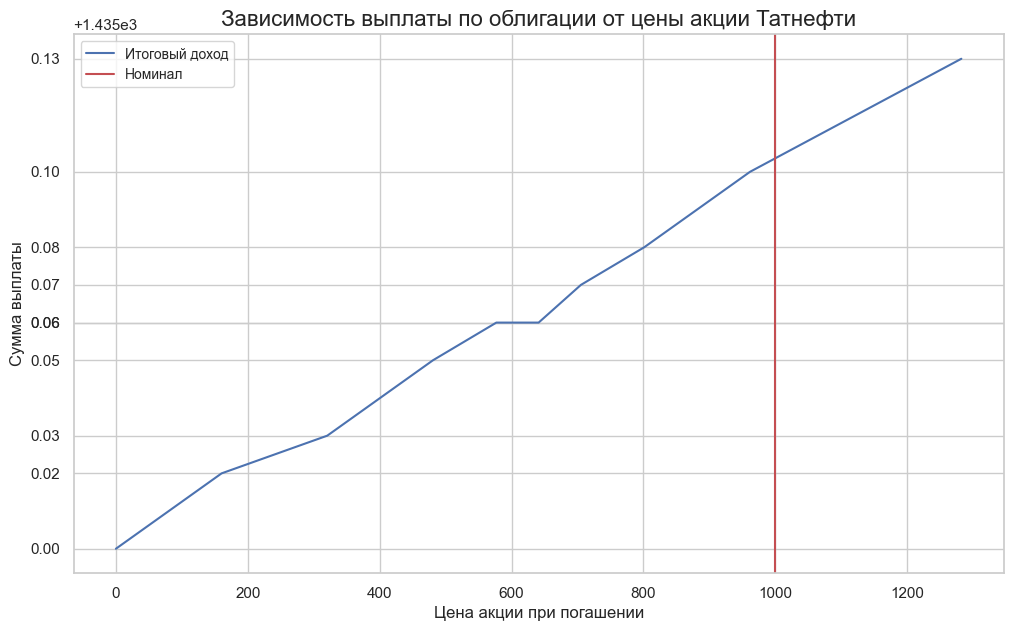

In [43]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))
plt.plot(df_price['Фин. цена (руб)'], df_price['Выплата при погашении'], label='Итоговый доход')
plt.axvline(x=1000, color='r', label='Номинал')

plt.title('Зависимость выплаты по облигации от цены акции Татнефти', fontsize=16)
plt.xlabel('Цена акции при погашении', fontsize=12)
plt.ylabel('Сумма выплаты', fontsize=12)

plt.legend(fontsize=10)
plt.yticks(df_price["Выплата при погашении"]);

In [44]:
df_div

,Факт. див. в % от плана,Факт див,Выплата при погашении,% от номинала
0,0%,0.00,947.57,51.26
1,25%,47.65,1069.44,63.44
2,50%,95.30,1191.32,75.63
3,75%,142.95,1313.19,87.82
4,100%,190.60,1435.06,100.01
5,125%,238.25,1556.94,112.19


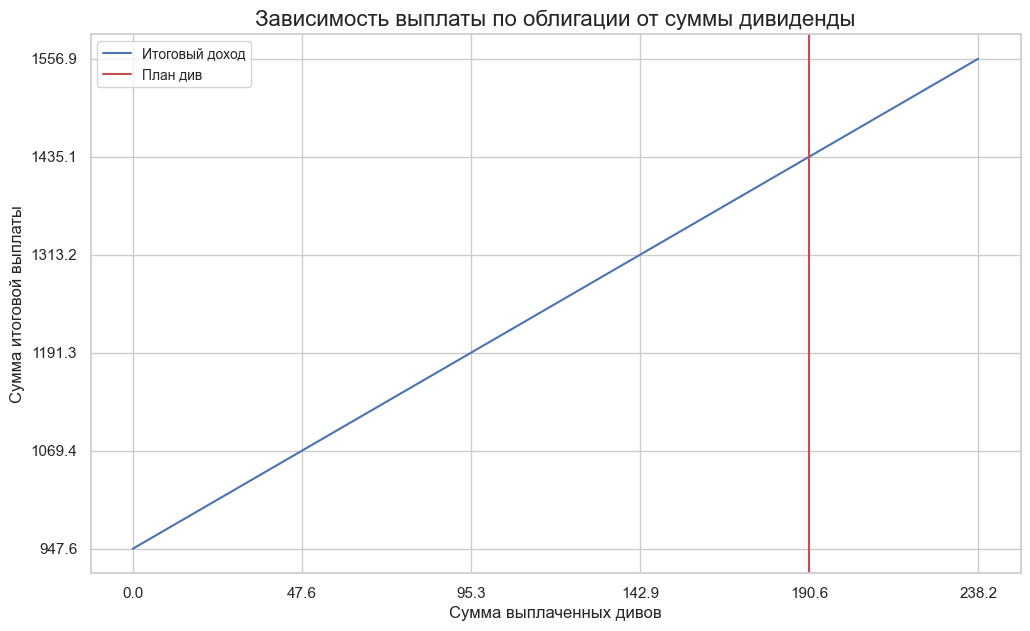

In [46]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))
plt.plot(df_div['Факт див'], df_div['Выплата при погашении'], label='Итоговый доход')
plt.axvline(x=190.60, color='r', label='План див')

plt.title('Зависимость выплаты по облигации от суммы дивиденды', fontsize=16)
plt.xlabel('Сумма выплаченных дивов', fontsize=12)
plt.ylabel('Сумма итоговой выплаты', fontsize=12)

plt.legend(fontsize=10)
plt.xticks(df_div["Факт див"])
plt.yticks(df_div["Выплата при погашении"]);

In [48]:
def monte_carlo_step(S, mu, sigma, dt, Z):
    return S * np.exp((mu-0.5*sigma**2)*dt+sigma*np.sqrt(dt)*Z)

In [ ]:
dt = 1/252
n_simulations = 1000
n_steps = int(918 * 252 / 365.25)

In [65]:
ohlcv_history = pd.read_csv("TATN_230929_240929.csv", sep=';')
ohlcv_history = ohlcv_history[ohlcv_history['<DATE>']!=241001]

In [71]:
log_returns = np.log( ohlcv_history['<CLOSE>'] / ohlcv_history['<CLOSE>'].shift(1) ).dropna()
sigma = log_returns.std() * np.sqrt(252)
historical_mu = log_returns.mean() * 252

In [72]:
simulation_results = np.zeros(n_simulations)

for i in range(n_simulations):
    z = np.random.standard_normal(n_steps)
    price_path = np.zeros(n_steps)
    price_path[0] = initial_price
    
    for t in range(1, n_steps):
        price_path[t] = monte_carlo_step(price_path[t-1], historical_mu, sigma, dt, z[t])
        
    final_simulated_price = price_path[-1]
    S = final_value_BA(final_simulated_price, Q, P, divs_plan, T)
    final_payout = payout(H, P, S, Q, divs_plan, T)
    total_payout = final_payout + extra_income
    simulation_results[i] = total_payout

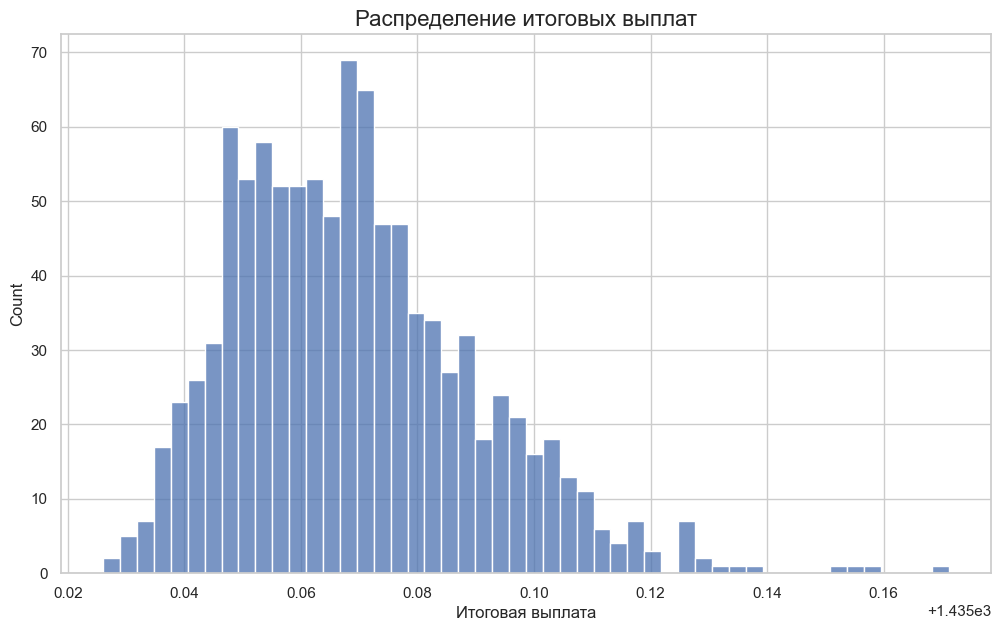

In [79]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 7))
sns.histplot(simulation_results, bins=50)

plt.title(f'Распределение итоговых выплат', fontsize=16)
plt.xlabel('Итоговая выплата', fontsize=12)
plt.show()

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

class StructuralBond:
    def __init__(self, name, isin, nominal=1000, tax_rate=0.13):
        self.name = name
        self.isin = isin
        self.H = nominal
        self.T = tax_rate
        self.params = {}

    def set_params(self, **kwargs):
        self.params.update(kwargs)

    def calculate_payout(self, market_growth_pct):
        """
        market_growth_pct: изменение цены базового актива (например, 0.1 для +10%, -0.2 для -20%)
        Возвращает итоговую выплату (нетто, после налогов)
        """
        raise NotImplementedError("Метод должен быть переопределен в подклассе")

# (RU000A109H37)
class ParticipationBond(StructuralBond):
    def calculate_payout(self, market_growth_pct):
        # Если рост (growth >= 0): Выплата = Номинал + 100% * (Рост)
        # Если падение (growth < 0): Выплата = Номинал * (1 + growth)

        final_price_ratio = 1.0 + market_growth_pct
        
        if market_growth_pct >= 0:
            res = self.H * 2.0 
        else:
            res = self.H * final_price_ratio
    
        income = max(0, res - self.H)
        tax = income * self.T
        return res - tax

# ru000a108hm7
class BasketAutocallBond(StructuralBond):
    def calculate_payout(self, market_growth_pct):
        coupon_rate_annual = 0.30 
        years = 3
        barrier_coupon = 0.10     
        barrier_capital = -0.10  
        if np.isscalar(market_growth_pct):
            basket_average = market_growth_pct
            basket_worst = market_growth_pct
        else:
            returns = np.array(market_growth_pct)
            basket_average = np.mean(returns)
            basket_worst = np.min(returns)

        total_coupon = self.H * coupon_rate_annual * years
        
        if basket_average >= barrier_coupon:
            # Сценарий: Среднее >= 110%
            # Выплата: Номинал + Все купоны
            gross = self.H + total_coupon
        elif basket_worst >= barrier_capital:
            # Сценарий: Упало, но выше 90%
            # Выплата: Номинал
            gross = self.H
        else:
            # Сценарий: Обвал ниже 90%
            # Выплата: По худшей
            gross = self.H * (1.0 + basket_worst)
            
        income = max(0, gross - self.H)
        return gross - income * self.T

# ru000a108hj3
class WorstOfAutocallBond(StructuralBond):
    def calculate_payout(self, market_growth_pct):
        coupon_rate_annual = 0.28 # 28% годовых
        years = 3
        barrier_coupon = 0.0  
        
        total_coupon = self.H * coupon_rate_annual * years
        if np.isscalar(market_growth_pct):
            basket_worst = market_growth_pct
        else:
            returns = np.array(market_growth_pct)
            basket_worst = np.min(returns)

        if basket_worst >= barrier_coupon:
            # Сценарий: Все акции >= 100%
            gross = self.H + total_coupon
        else:
            # Сценарий: Хотя бы одна упала < 100%
            # Выплата: По худшей (убыток)
            gross = self.H * (1.0 + basket_worst)
            
        income = max(0, gross - self.H)
        return gross - income * self.T

bonds = []

# RU000A109H37 (Сбер)
b1 = ParticipationBond("RU000A109H37 (Сбер)", "RU000A109H37")
bonds.append(b1)

# RU000A108HM7 (Корзина 5 акций)
b2 = BasketAutocallBond("RU000A108HM7 (Корзина 5)", "RU000A108HM7")
bonds.append(b2)

# RU000A108HJ3 (Сбер + Яндекс)
b3 = WorstOfAutocallBond("RU000A108HJ3 (Сбер+Яндекс)", "RU000A108HJ3")
bonds.append(b3)

market_moves = np.linspace(-0.50, 0.50, 200) 
results = {'Market Move %': market_moves * 100}

for bond in bonds:
    payouts = [bond.calculate_payout(move) for move in market_moves]
    results[bond.name] = payouts

df_all = pd.DataFrame(results)

In [22]:
df_all[df_all['Market Move %']<-3]

,Market Move %,RU000A109H37 (Сбер),RU000A108HM7 (Корзина 5),RU000A108HJ3 (Сбер+Яндекс)
0,-50.000000,500.000000,500.000000,500.000000
1,-49.497487,505.025126,505.025126,505.025126
2,-48.994975,510.050251,510.050251,510.050251
3,-48.492462,515.075377,515.075377,515.075377
4,-47.989950,520.100503,520.100503,520.100503
...,...,...,...,...
89,-5.276382,947.236181,1000.000000,947.236181
90,-4.773869,952.261307,1000.000000,952.261307
91,-4.271357,957.286432,1000.000000,957.286432
92,-3.768844,962.311558,1000.000000,962.311558


In [16]:
scenarios = [
    -0.30,  
    -0.15, 
    -0.05, 
     0.00, 
     0.05, 
     0.12, 
     0.30 
]
data = []
for pct in scenarios:
    row = {
        "Движение рынка": f"{pct:+.0%}",
        "Raw_Sort": pct
    }
    for bond in bonds:
        payout = bond.calculate_payout(pct)
        profit_pct = (payout - 1000) / 1000
        row[bond.name] = f"{payout:.0f} ₽ ({profit_pct:+.0%})"
        row[f"{bond.name}_val"] = profit_pct 
        
    data.append(row)

df = pd.DataFrame(data)

display_cols = ["Движение рынка"] + [b.name for b in bonds]
final_df = df[display_cols]


In [17]:
final_df

,Движение рынка,RU000A109H37 (Сбер),RU000A108HM7 (Корзина 5),RU000A108HJ3 (Сбер+Яндекс)
0,-30%,700 ₽ (-30%),700 ₽ (-30%),700 ₽ (-30%)
1,-15%,850 ₽ (-15%),850 ₽ (-15%),850 ₽ (-15%)
2,-5%,950 ₽ (-5%),1000 ₽ (+0%),950 ₽ (-5%)
3,+0%,1870 ₽ (+87%),1000 ₽ (+0%),1731 ₽ (+73%)
4,+5%,1870 ₽ (+87%),1000 ₽ (+0%),1731 ₽ (+73%)
5,+12%,1870 ₽ (+87%),1783 ₽ (+78%),1731 ₽ (+73%)
6,+30%,1870 ₽ (+87%),1783 ₽ (+78%),1731 ₽ (+73%)
